# Tarea 1 – Parte 1: Recolección y limpieza de noticias (La República)

**Pregunta guía:** ¿Pueden convertir titulares peruanos en un clasificador de noticias?

| Campo | Valor |
| :-- | :-- |
| **Fecha de descarga** | 2026-10-18 |
| **Opción elegida** | **A – La República** (`larepublica.pe`) |
| **Meta** | ~100 noticias por categoría (`politica`, `economia`, `deportes`, `ciencia_tecnologia`), mínimo 350 en total |
| **URL base** | `https://larepublica.pe` |
| **Feeds RSS** | `https://larepublica.pe/rss/{seccion}.xml` (`politica`, `economia`, `deportes`, `ciencia`, `home`) |
| **Sitemaps** | `https://larepublica.pe/sitemap/{seccion}.xml` y `https://larepublica.pe/sitemap/noticias.xml` |
| **Descubrimiento histórico** | API CDX de Internet Archive (`web.archive.org/cdx`) solo para *listar URLs* de `larepublica.pe` |

### Fuentes usadas y por qué
1. **RSS + sitemaps oficiales de La República** (fuente principal). El RSS y el sitemap de cada sección traen solo las últimas 6–21 notas, y los feeds `home`/`noticias` mezclan todas las secciones. En total aportan ~120 notas de las 4 categorías: **no alcanzan** para llegar a ~100 por categoría.
2. **Completar con URLs históricas de 2024–2026.** `larepublica.pe` no ofrece un archivo paginado permitido (`/*/pag/*` y `/*/tag/*` están en `Disallow` de su `robots.txt`). Para listar URLs antiguas de las mismas secciones se consultó el índice CDX de Internet Archive (solo la lista de URLs). Cada nota se **descarga luego directamente de `larepublica.pe`**, de forma respetuosa, y de su HTML se leen `og:title` (titular) y `og:description` (bajada).
3. La fecha se toma de la propia URL (`/seccion/AAAA/MM/DD/...`).

### Buenas prácticas aplicadas
- Se revisa `robots.txt` antes de pedir cualquier URL (celda 3).
- `User-Agent` descriptivo con contacto, **pausa aleatoria de 1–2 s** entre solicitudes y **máximo 1 reintento**.
- Respaldo crudo en `datos/raw/` (XML de RSS/sitemaps, listas CDX y un `.jsonl` con lo extraído de cada nota).

In [1]:
import json, random, re, time
from datetime import datetime
from pathlib import Path
from urllib.parse import urlparse

import pandas as pd
import plotly.express as px
import plotly.io as pio
import requests
from bs4 import BeautifulSoup

# Renderer estático (PNG) para que los gráficos se vean en GitHub;
# 'plotly_mimetype' conserva la versión interactiva al abrir el notebook en VS Code/Jupyter.
pio.renderers.default = "png+plotly_mimetype"
pio.templates.default = "plotly_white"

BASE = "https://larepublica.pe"
UA = "Mozilla/5.0 (tarea-universitaria-python-intermedio; uso academico; contacto: makenoisehere@gmail.com)"
HEADERS = {"User-Agent": UA}
SEED = 42
META_POR_CATEGORIA = 100
FECHA_DESCARGA = datetime.now().strftime("%Y-%m-%d")

RAW = Path("datos/raw"); RAW.mkdir(parents=True, exist_ok=True)
Path("datos").mkdir(exist_ok=True)
random.seed(SEED)

ultima_peticion = {"t": 0.0}

def get(url, host_propio=True, timeout=40):
    """GET con pausa de 1-2 s (si es larepublica.pe) y como maximo 1 reintento."""
    for intento in range(2):                      # intento 0 + 1 reintento
        espera = random.uniform(1, 2) if host_propio else 2.0
        resta = espera - (time.time() - ultima_peticion["t"])
        if resta > 0:
            time.sleep(resta)
        try:
            r = requests.get(url, headers=HEADERS, timeout=timeout)
            ultima_peticion["t"] = time.time()
            if r.status_code in (429, 500, 502, 503, 504) and intento == 0:
                continue
            return r
        except requests.RequestException:
            ultima_peticion["t"] = time.time()
            if intento == 1:
                return None
    return None
print("Descarga:", FECHA_DESCARGA)

Descarga: 2026-10-18


## 1. Revisión de `robots.txt`

In [2]:
r = get(f"{BASE}/robots.txt")
robots_txt = r.text
(RAW / "robots_larepublica.txt").write_text(robots_txt, encoding="utf-8")

# Reglas del grupo "User-agent: *" (el archivo lista muchos bots en un mismo grupo)
reglas = [(l.split(":", 1)[0].strip().lower(), l.split(":", 1)[1].strip())
          for l in robots_txt.splitlines() if l.lower().startswith(("disallow:", "allow:")) and l.split(":", 1)[1].strip()]

def _regex(patron):
    p = re.escape(patron).replace(r"\*", ".*")
    return re.compile("^" + p.replace(r"\$", "$"))

reglas_re = [(t, _regex(p), len(p)) for t, p in reglas]

def permitido(url):
    """Regla de Google: gana la coincidencia mas larga; empate -> Allow."""
    path = urlparse(url).path or "/"
    mejor = (-1, True)
    for tipo, rx, largo in reglas_re:
        if rx.match(path) and (largo > mejor[0] or (largo == mejor[0] and tipo == "allow")):
            mejor = (largo, tipo == "allow")
    return mejor[1]

print(f"{len(reglas)} reglas Allow/Disallow leídas. Lo relevante:")
for linea in robots_txt.splitlines():
    if any(k in linea for k in ("/rss/", "/sitemap/", "/pag/", "/tag/", "/buscador", "/sitemaps/*", "/pf/")):
        print("  ", linea)

pruebas = [f"{BASE}/rss/politica.xml", f"{BASE}/sitemap/economia.xml",
           f"{BASE}/politica/2026/10/18/ejemplo-hnews-1", f"{BASE}/politica/pag/2/", f"{BASE}/politica/tag/congreso/"]
for u in pruebas:
    print(("PERMITIDO " if permitido(u) else "BLOQUEADO ") + u)

27 reglas Allow/Disallow leídas. Lo relevante:
   Disallow: /buscador*
   Disallow: /*/pag/
   Disallow: /*/pag/*
   Disallow: /*/tag/*
   Disallow: */sitemaps/*
   Disallow: */pf/*
   Allow: /sitemap/
   Allow: /sitemap/*
   Allow: /sitemaps/*
   Allow: /rss/
   Allow: /rss/*
   Sitemap: https://larepublica.pe/sitemap/sociedad.xml
   Sitemap: https://larepublica.pe/sitemap/noticias.xml
   Sitemap: https://larepublica.pe/sitemap/politica.xml
   Sitemap: https://larepublica.pe/sitemap/opinion.xml
   Sitemap: https://larepublica.pe/sitemap/mundo.xml
   Sitemap: https://larepublica.pe/sitemap/mastergrama.xml
   Sitemap: https://larepublica.pe/sitemap/espectaculos.xml
   Sitemap: https://larepublica.pe/sitemap/economia.xml
   Sitemap: https://larepublica.pe/sitemap/deportes.xml
   Sitemap: https://larepublica.pe/sitemap/cine-series.xml
   Sitemap: https://larepublica.pe/sitemap/carlincatura.xml
   Sitemap: https://larepublica.pe/sitemap/ciencia.xml
   Sitemap: https://larepublica.pe/sitema

**Conclusión:** los RSS (`/rss/`), los sitemaps (`/sitemap/`) y las páginas de nota están permitidos. Están bloqueados la paginación (`/*/pag/`), las etiquetas (`/*/tag/`), el buscador y `/pf/` (API interna). Por eso **no se pagina el sitio ni se usan sus APIs internas**: solo RSS, sitemaps y notas individuales.

## 2. Extracción – Fuente 1: RSS y sitemaps oficiales

In [3]:
SECCIONES_FEED = ["politica", "economia", "deportes", "ciencia", "home"]
SITEMAPS = ["politica", "economia", "deportes", "ciencia", "noticias"]

URL_NOTA = re.compile(r"^https?://larepublica\.pe(?::80)?/(?:amp/)?([a-z0-9-]+)/(\d{4})/(\d{2})/(\d{2})/([^/?#]+)/?$")

def normaliza(url):
    """Quita ':80', 'http' y el prefijo /amp/ para que la misma nota no se cuente dos veces."""
    m = URL_NOTA.match(url.strip())
    if not m:
        return None
    sec, y, mth, d, slug = m.groups()
    return f"{BASE}/{sec}/{y}/{mth}/{d}/{slug}"

registros = {}   # url -> dict con lo que se sepa de la nota

for sec in SECCIONES_FEED:
    r = get(f"{BASE}/rss/{sec}.xml")
    if r is None or r.status_code != 200:
        print("RSS", sec, "falló"); continue
    (RAW / f"rss_{sec}.xml").write_text(r.text, encoding="utf-8")
    soup = BeautifulSoup(r.text, "xml")
    n = 0
    for it in soup.find_all("item"):
        url = normaliza(it.find("link").get_text(strip=True)) if it.find("link") else None
        if not url:
            continue
        registros.setdefault(url, {
            "titular": it.find("title").get_text(strip=True),
            "bajada": it.find("description").get_text(strip=True) if it.find("description") else "",
            "fuente": "rss"})
        n += 1
    print(f"RSS {sec:<9} -> {n:>3} notas")

for sec in SITEMAPS:
    r = get(f"{BASE}/sitemap/{sec}.xml")
    if r is None or r.status_code != 200:
        print("Sitemap", sec, "falló"); continue
    (RAW / f"sitemap_{sec}.xml").write_text(r.text, encoding="utf-8")
    n = 0
    for loc in BeautifulSoup(r.text, "xml").find_all("loc"):
        url = normaliza(loc.get_text(strip=True))
        if url:
            registros.setdefault(url, {"titular": "", "bajada": "", "fuente": "sitemap"}); n += 1
    print(f"Sitemap {sec:<9} -> {n:>3} URLs")

print("\nURLs únicas de la fuente 1:", len(registros))

RSS politica  ->  22 notas


RSS economia  ->   4 notas


RSS deportes  ->  14 notas


RSS ciencia   ->  10 notas


RSS home      -> 198 notas


Sitemap politica  ->  22 URLs


Sitemap economia  ->   4 URLs


Sitemap deportes  ->  14 URLs


Sitemap ciencia   ->  10 URLs


Sitemap noticias  -> 198 URLs

URLs únicas de la fuente 1: 198


In [4]:
def seccion_de(url):
    return url.split("/")[3]

# Para ver cuántas de las notas de la fuente 1 caen en las 4 categorías
MAPEO = {  # seccion_original (primer segmento de la URL) -> etiqueta estandarizada
    "politica": "politica",
    "economia": "economia",
    "deportes": "deportes",
    "ciencia": "ciencia_tecnologia",
    "tecnologia": "ciencia_tecnologia",
}
vista = pd.Series([MAPEO.get(seccion_de(u), "(fuera de las 4 categorías)") for u in registros]).value_counts()
print(vista.to_string())

(fuera de las 4 categorías)    148
politica                        22
deportes                        14
ciencia_tecnologia              10
economia                         4


## 3. Extracción – Fuente 2: completar con URLs históricas

La fuente 1 deja a las categorías lejos de ~100 notas cada una. Se listan URLs de 2024–2026 de las 5 secciones relevantes (`politica`, `economia`, `deportes`, `ciencia`, `tecnologia`) con el índice CDX de Internet Archive y se **descargan desde `larepublica.pe`** respetando `robots.txt`, pausas y reintento máximo de 1.

In [5]:
CDX = "http://web.archive.org/cdx/search/cdx"
CONSULTAS = {  # seccion -> años a consultar
    "politica": [2026], "economia": [2026, 2025], "deportes": [2026],
    "ciencia": [2026, 2025, 2024], "tecnologia": [2026, 2025, 2024],
}
candidatas = {}   # url -> seccion
for sec, years in CONSULTAS.items():
    for y in years:
        archivo = RAW / f"cdx_{sec}_{y}.txt"
        if archivo.exists():
            texto = archivo.read_text(encoding="utf-8")
        else:
            texto = ""
            for _ in range(3):                    # el CDX a veces tarda o expira; no se cachean respuestas vacías
                r = get(f"{CDX}?url=larepublica.pe/{sec}/{y}/*&fl=original&collapse=urlkey&filter=statuscode:200&limit=2500",
                        host_propio=False, timeout=150)
                if r is not None and r.status_code == 200 and r.text.strip():
                    texto = r.text; archivo.write_text(texto, encoding="utf-8"); break
        n0 = len(candidatas)
        for linea in texto.splitlines():
            u = normaliza(linea)
            if u and seccion_de(u) == sec and u not in registros:
                candidatas[u] = sec
        print(f"CDX {sec:<10} {y}: +{len(candidatas)-n0} URLs candidatas")
print("Total candidatas:", len(candidatas))

CDX politica   2026: +2156 URLs candidatas
CDX economia   2026: +1241 URLs candidatas
CDX economia   2025: +2485 URLs candidatas
CDX deportes   2026: +2403 URLs candidatas
CDX ciencia    2026: +1400 URLs candidatas
CDX ciencia    2025: +1817 URLs candidatas
CDX ciencia    2024: +1320 URLs candidatas
CDX tecnologia 2026: +45 URLs candidatas
CDX tecnologia 2025: +895 URLs candidatas
CDX tecnologia 2024: +184 URLs candidatas
Total candidatas: 13946


### Descarga de notas individuales
Se fija una meta de **100 notas válidas por categoría**. Primero se completan las notas de la fuente 1 que no traen titular/bajada (sitemaps) y luego se sortea (semilla 42) entre las candidatas históricas hasta cubrir la cuota. Cada nota se guarda en `datos/raw/articulos_raw.jsonl`; los fallos (HTTP ≠ 200, sin titular, sin bajada) quedan registrados como descartes con su motivo.

In [6]:
RAW_JSONL = RAW / "articulos_raw.jsonl"
cache = {}
if RAW_JSONL.exists():                       # permite reanudar si se corta la ejecución
    for l in RAW_JSONL.read_text(encoding="utf-8").splitlines():
        d = json.loads(l); cache[d["url"]] = d

def limpia(t):
    return re.sub(r"\s+", " ", t or "").strip()

def descarga_nota(url):
    if url in cache:
        return cache[url]
    d = {"url": url, "titular": "", "bajada": "", "estado": None, "error": None}
    if not permitido(url):
        d["error"] = "bloqueado por robots.txt"
    else:
        r = get(url)
        if r is None:
            d["error"] = "sin respuesta"
        else:
            d["estado"] = r.status_code
            if r.status_code != 200:
                d["error"] = f"HTTP {r.status_code}"
            else:
                s = BeautifulSoup(r.text, "lxml")
                og = lambda p: (s.find("meta", attrs={"property": p}) or {}).get("content", "")
                d["titular"] = limpia(og("og:title") or (s.h1.get_text() if s.h1 else ""))
                d["bajada"] = limpia(og("og:description") or (s.find("meta", attrs={"name": "description"}) or {}).get("content", ""))
    cache[url] = d
    with RAW_JSONL.open("a", encoding="utf-8") as f:
        f.write(json.dumps(d, ensure_ascii=False) + "\n")
    return d

def etiqueta_de(url):
    return MAPEO.get(seccion_de(url))

def validas_por_categoria():
    cuenta = {c: 0 for c in set(MAPEO.values())}
    for u, reg in todos.items():
        if etiqueta_de(u) and reg.get("titular") and reg.get("bajada"):
            cuenta[etiqueta_de(u)] += 1
    return cuenta

todos = {u: dict(r) for u, r in registros.items()}

# (a) notas de las 4 categorías de la fuente 1 sin titular/bajada (venían solo del sitemap)
pend = [u for u, r in todos.items() if etiqueta_de(u) and not (r["titular"] and r["bajada"])]
print("Notas de fuente 1 por completar:", len(pend))
for u in pend:
    d = descarga_nota(u)
    todos[u].update(titular=d["titular"], bajada=d["bajada"], error=d["error"])
print("Válidas tras fuente 1:", validas_por_categoria())

Notas de fuente 1 por completar: 0
Válidas tras fuente 1: {'ciencia_tecnologia': 10, 'deportes': 14, 'economia': 4, 'politica': 22}


In [7]:
# (b) completar cada categoría con candidatas históricas, sorteadas con semilla fija
rng = random.Random(SEED)
por_cat = {}
for u, sec in candidatas.items():
    por_cat.setdefault(MAPEO[sec], []).append(u)
for c in por_cat:
    por_cat[c].sort(); rng.shuffle(por_cat[c])

for cat, urls in por_cat.items():
    usadas = 0
    for u in urls:
        if validas_por_categoria()[cat] >= META_POR_CATEGORIA:
            break
        d = descarga_nota(u)
        todos[u] = {"titular": d["titular"], "bajada": d["bajada"], "fuente": "historico", "error": d["error"]}
        usadas += 1
        if usadas % 25 == 0:
            print(f"  {cat}: {usadas} notas pedidas, válidas={validas_por_categoria()[cat]}")
    print(f"{cat}: {usadas} pedidas -> {validas_por_categoria()[cat]} válidas")
print("\nVálidas por categoría:", validas_por_categoria())

  politica: 25 notas pedidas, válidas=44
  politica: 50 notas pedidas, válidas=69
  politica: 75 notas pedidas, válidas=94
politica: 81 pedidas -> 100 válidas
  economia: 25 notas pedidas, válidas=29
  economia: 50 notas pedidas, válidas=54
  economia: 75 notas pedidas, válidas=79
economia: 96 pedidas -> 100 válidas
  deportes: 25 notas pedidas, válidas=39
  deportes: 50 notas pedidas, válidas=64
  deportes: 75 notas pedidas, válidas=89
deportes: 86 pedidas -> 100 válidas
  ciencia_tecnologia: 25 notas pedidas, válidas=35
  ciencia_tecnologia: 50 notas pedidas, válidas=60
  ciencia_tecnologia: 75 notas pedidas, válidas=85
ciencia_tecnologia: 90 pedidas -> 100 válidas

Válidas por categoría: {'ciencia_tecnologia': 100, 'deportes': 100, 'economia': 100, 'politica': 100}


## 4. Verificación de URLs de la fuente 1
Las notas que vinieron del RSS no se descargaron individualmente. Se comprueba que sus enlaces responden `200` con una muestra aleatoria de 30.

In [8]:
rss_urls = [u for u, r in todos.items() if r.get("fuente") == "rss" and etiqueta_de(u)]
muestra = random.Random(SEED).sample(rss_urls, min(30, len(rss_urls)))
codigos = {}
for u in muestra:
    r = get(u)
    codigos[u] = r.status_code if r is not None else None
print(pd.Series(codigos).value_counts(dropna=False).rename("n_urls").to_frame())

     n_urls
200      30


## 5. Limpieza y normalización

In [9]:
filas = []
for u, r in todos.items():
    filas.append({
        "titular": limpia(r.get("titular")), "bajada": limpia(r.get("bajada")), "medio": "La Republica",
        "seccion_original": seccion_de(u), "url": u,
        "fecha": "-".join(u.split("/")[4:7]),          # AAAA-MM-DD tomada de la URL
        "etiqueta": etiqueta_de(u), "error": r.get("error"),
    })
bruto = pd.DataFrame(filas)
print("Registros brutos (todas las secciones):", len(bruto))

descartes = []   # (motivo, n)
d = bruto.copy()

n = (~d["etiqueta"].notna()).sum()
descartes.append(("Sección fuera de las 4 categorías (no se inventa una quinta)", n)); d = d[d["etiqueta"].notna()]

n = d["error"].notna().sum()
descartes.append(("Nota inaccesible al descargarla (HTTP ≠ 200 / sin respuesta)", n)); d = d[d["error"].isna()]

n = (d["titular"] == "").sum()
descartes.append(("Titular vacío", n)); d = d[d["titular"] != ""]

n = (d["bajada"] == "").sum()
descartes.append(("Sin bajada (columna obligatoria)", n)); d = d[d["bajada"] != ""]

n = d.duplicated("url").sum()
descartes.append(("URL duplicada", n)); d = d.drop_duplicates("url")

n = d.duplicated("titular").sum()
descartes.append(("Titular duplicado (misma nota con otra URL)", n)); d = d.drop_duplicates("titular")

# Recorte final: máximo META_POR_CATEGORIA por categoría (las más recientes de cada una se conservan por orden de llegada)
exceso = d.groupby("etiqueta").cumcount() >= META_POR_CATEGORIA
descartes.append((f"Exceso sobre la cuota de {META_POR_CATEGORIA} por categoría", exceso.sum())); d = d[~exceso]

reporte = pd.DataFrame(descartes, columns=["motivo_de_descarte", "n_noticias"])
print("Reporte de descartes:")
display(reporte)
print(f"Conservadas: {len(d)} de {len(bruto)} registros brutos")

Registros brutos (todas las secciones): 551
Reporte de descartes:


,motivo_de_descarte,n_noticias
0,Sección fuera de las 4 categorías (no se inven...,148
1,Nota inaccesible al descargarla (HTTP ≠ 200 / ...,3
2,Titular vacío,0
3,Sin bajada (columna obligatoria),0
4,URL duplicada,0
5,Titular duplicado (misma nota con otra URL),0
6,Exceso sobre la cuota de 100 por categoría,0


Conservadas: 400 de 551 registros brutos


### Tabla de equivalencias `seccion_original` → `etiqueta`

In [10]:
vistas = bruto["seccion_original"].value_counts().rename("n_encontradas")
tabla = (pd.DataFrame({"seccion_original": vistas.index, "n_encontradas": vistas.values})
         .assign(etiqueta=lambda x: x["seccion_original"].map(MAPEO).fillna("— descartada —"))
         .assign(conservadas=lambda x: x["seccion_original"].map(d["seccion_original"].value_counts()).fillna(0).astype(int))
         .sort_values(["etiqueta", "n_encontradas"], ascending=[True, False]).reset_index(drop=True))
display(tabla)

,seccion_original,n_encontradas,etiqueta,conservadas
0,ciencia,86,ciencia_tecnologia,86
1,tecnologia,14,ciencia_tecnologia,14
2,deportes,100,deportes,100
3,economia,100,economia,100
4,politica,103,politica,100
5,sociedad,44,— descartada —,0
6,espectaculos,31,— descartada —,0
7,mundo,23,— descartada —,0
8,opinion,13,— descartada —,0
9,latinos-en-usa,8,— descartada —,0


In [11]:
df = d[["titular", "bajada", "medio", "seccion_original", "url", "fecha", "etiqueta"]].reset_index(drop=True)
df["fecha"] = pd.to_datetime(df["fecha"]).dt.strftime("%Y-%m-%d")
print(df["etiqueta"].value_counts().to_string())
assert len(df) >= 360, "No se alcanzaron 360 noticias"

etiqueta
politica              100
economia              100
deportes              100
ciencia_tecnologia    100


## 6. Análisis exploratorio (3 gráficos con Plotly Express)

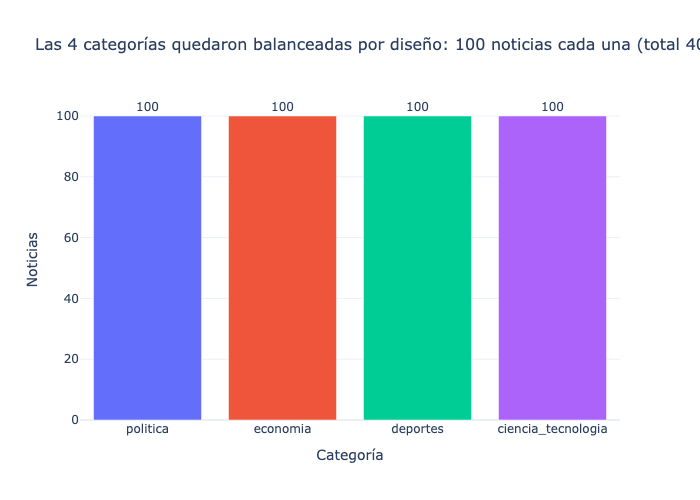

In [12]:
ORDEN = ["politica", "economia", "deportes", "ciencia_tecnologia"]
conteo = df["etiqueta"].value_counts().reindex(ORDEN).reset_index()
conteo.columns = ["etiqueta", "n"]
fig = px.bar(conteo, x="etiqueta", y="n", text="n", color="etiqueta",
             title=(f"Las 4 categorías quedaron balanceadas por diseño: {conteo.n.max()} noticias cada una (total {conteo.n.sum()})" if conteo.n.min()==conteo.n.max() else f"Las 4 categorías quedaron casi balanceadas: entre {conteo.n.min()} y {conteo.n.max()} noticias cada una (total {conteo.n.sum()})"),
             labels={"etiqueta": "Categoría", "n": "Noticias"})
fig.update_layout(showlegend=False, title_font_size=16); fig.update_traces(textposition="outside")
fig.show()

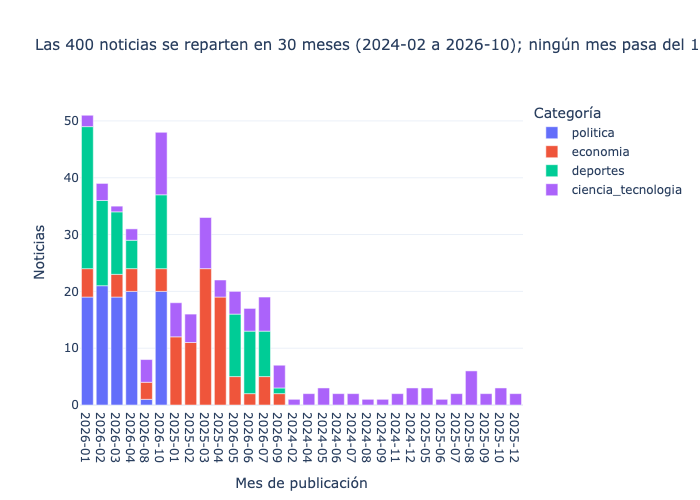

In [13]:
df["mes"] = pd.to_datetime(df["fecha"]).dt.to_period("M").astype(str)
por_mes = df.groupby(["mes", "etiqueta"]).size().reset_index(name="n")
tot_mes = df["mes"].value_counts()
mes_top, pct_top = tot_mes.index[0], 100 * tot_mes.iloc[0] / len(df)
fig = px.bar(por_mes, x="mes", y="n", color="etiqueta", category_orders={"etiqueta": ORDEN},
             title=f"Las {len(df)} noticias se reparten en {len(tot_mes)} meses ({df['fecha'].min()[:7]} a {df['fecha'].max()[:7]}); ningún mes pasa del {pct_top:.0f}% (pico: {mes_top})",
             labels={"mes": "Mes de publicación", "n": "Noticias", "etiqueta": "Categoría"})
fig.update_layout(title_font_size=15); fig.update_xaxes(type="category")
fig.show()

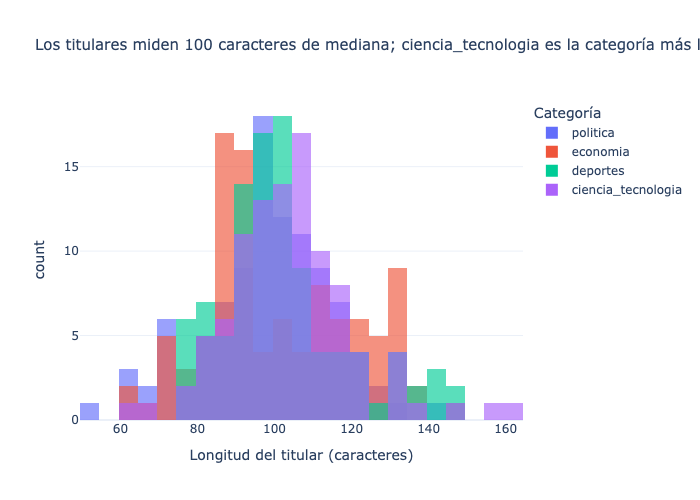

etiqueta
politica               98.0
economia               97.0
deportes              100.0
ciencia_tecnologia    103.0


In [14]:
df["largo_titular"] = df["titular"].str.len()
med = df.groupby("etiqueta")["largo_titular"].median().reindex(ORDEN)
fig = px.histogram(df, x="largo_titular", color="etiqueta", nbins=40, barmode="overlay", opacity=0.65,
                   category_orders={"etiqueta": ORDEN},
                   title=f"Los titulares miden {df.largo_titular.median():.0f} caracteres de mediana; {med.idxmax()} es la categoría más larga ({med.max():.0f}) y {med.idxmin()} la más corta ({med.min():.0f})",
                   labels={"largo_titular": "Longitud del titular (caracteres)", "count": "Noticias", "etiqueta": "Categoría"})
fig.update_layout(title_font_size=15)
fig.show()
print(med.round(1).to_string())

## 7. Validación: titulares más largos y más cortos

In [15]:
pd.set_option("display.max_colwidth", 200)
print("Histograma: rango", df.largo_titular.min(), "–", df.largo_titular.max(), "caracteres; mediana", df.largo_titular.median())
print("\n5 titulares MÁS LARGOS")
display(df.nlargest(5, "largo_titular")[["largo_titular", "etiqueta", "titular"]])
print("5 titulares MÁS CORTOS")
display(df.nsmallest(5, "largo_titular")[["largo_titular", "etiqueta", "titular"]])

Histograma: rango 53 – 164 caracteres; mediana 100.0

5 titulares MÁS LARGOS


,largo_titular,etiqueta,titular
41,164,ciencia_tecnologia,"En 1986, la explosión del reactor de Chernóbil obligó a que los perros fueran abandonados por sus dueños; décadas después, estos formaron grupos genéticos distintos"
381,159,ciencia_tecnologia,"Después de la Gran Muralla China, África construye un “Muro de Árboles” de 8.000 km para frenar al Sahara, restaurar tierras y alimentar a millones de personas"
33,149,deportes,"Pablo Guede ningunea a Franco Velazco, administrador de Universitario, tras polémicas declaraciones en su contra: ""No sé quién es, ¿habla de fútbol?"""
39,148,deportes,"Mia Shalit, arquera de Universitario, destaca el nivel de las cremas pese a derrota ante Palmeiras por Copa Libertadores Femenina: ""Estuvimos cerca"""
40,147,ciencia_tecnologia,Los lobos gigantes modificados genéticamente pasaron un chequeo médico por sus 2 años: “Ahora podemos ver que son de tamaño natural. Tuvimos éxito”


5 titulares MÁS CORTOS


,largo_titular,etiqueta,titular
78,53,politica,Roberto Sánchez: “La autonomía del BCR la defendemos”
2,60,politica,Seis regiones llegaron al 100% del conteo oficial de la ONPE
164,60,economia,¿Cómo saber el estado de tus aportes a la ONP? Consulta aquí
6,61,politica,Fernando Cerimedo tenía operadores en las elecciones del Perú
394,62,ciencia_tecnologia,¿Qué significa 14643 en el amor y por qué lo usan en WhatsApp?


**Coherencia con el histograma:** el titular más largo y el más corto coinciden con los extremos del eje X del histograma (mínimo y máximo impresos arriba). Los más largos son titulares explicativos con varias oraciones y comillas; los más cortos son titulares telegráficos, típicos de resultados deportivos o notas breves. Ambos son notas reales y no errores de extracción (se puede verificar abriendo su `url`).

## 8. Exportación

In [16]:
COLUMNAS = ["titular", "bajada", "medio", "seccion_original", "url", "fecha", "etiqueta"]
out = df[COLUMNAS]
out.to_csv("datos/noticias.csv", index=False, encoding="utf-8")

chequeo = pd.read_csv("datos/noticias.csv")
assert list(chequeo.columns) == COLUMNAS and len(chequeo) >= 360
assert chequeo["url"].is_unique and chequeo["titular"].notna().all()
print("df.shape =", chequeo.shape)
display(chequeo.head())
print(chequeo["etiqueta"].value_counts().to_string())

df.shape = (400, 7)


,titular,bajada,medio,seccion_original,url,fecha,etiqueta
0,Keiko Fujimori coordinó con Delcy Rodríguez la expulsión de venezolanos indocumentados,"La mandataria informó que su Gobierno iniciará el apoyo al programa Vuelta a la Patria, iniciativa venezolana orientada al retorno de sus ciudadanos a su país de origen.",La Republica,politica,https://larepublica.pe/politica/2026/10/18/keiko-fujimori-coordina-con-delcy-rodriguez-la-expulsion-de-venezolanos-indocumentados-hnews-1255032,2026-10-18,politica
1,Detención de seis policías por presunto robo reaviva debate sobre reforma de la PNP,"La situación ha llevado a que la desconfianza en la PNP aumente porcentualmente a picos históricos. Experto señala que una reforma policial debe abordar la integridad institucional, orientar la pr...",La Republica,politica,https://larepublica.pe/politica/2026/10/18/detencion-de-seis-policias-por-presunto-robo-reaviva-debate-sobre-reforma-de-la-pnp-hnews-974772,2026-10-18,politica
2,Seis regiones llegaron al 100% del conteo oficial de la ONPE,"Amazonas, Ayacucho, Moquegua, Pasco, Puno y Tacna son las únicas que han alcanzado el máximo conteo tanto para las elecciones municipales como en las regionales. De este grupo, solo Ayacucho no ir...",La Republica,politica,https://larepublica.pe/politica/2026/10/18/6-regiones-llegaron-al-100-del-conteo-oficial-de-la-onpe-hnews-1130994,2026-10-18,politica
3,Comisión de Constitución del Senado continuará debate de pedido de facultades este lunes 19,"El debate se reanudará desde las 11 de la mañana en la sala Francisco Bolognesi del Palacio Legislativo. Citación fue cursada por el presidente del grupo de trabajo, Carlos Mesía.",La Republica,politica,https://larepublica.pe/politica/2026/10/18/comision-de-constitucion-del-senado-continuara-debate-de-pedido-de-facultades-este-lunes-19-hnews-577638,2026-10-18,politica
4,Jorge Nieto plantea aprobar las 20 facultades respaldadas por Diputados y tramitar las adicionales como proyectos de ley,"El líder del Partido del Buen Gobierno señaló que hizo llegar esta propuesta a representantes del Gobierno de Keiko Fujimori. Además, pidió esclarecer la dinámica entre cámaras del Parlamento para...",La Republica,politica,https://larepublica.pe/politica/2026/10/18/jorge-nieto-plantea-aprobar-las-20-facultades-respaldadas-por-diputados-y-tramitar-las-adicionales-como-proyectos-de-ley-hnews-1130742,2026-10-18,politica


etiqueta
politica              100
economia              100
deportes              100
ciencia_tecnologia    100
